In [33]:
!unzip -qo /content/DL051-LoRA-colab.zip -d /content/
%cd /content/DL051-LoRA
%env DL051_MODE=full

/content/DL051-LoRA
env: DL051_MODE=full


# DL-051 — LoRA: Low-Rank Adaptation of Large Language Models
**Reduced-scale reproduction and rank ablation on DistilBERT + GLUE SST-2**

* Student: Manya Dixit (24CS2026), Programme: IDD
* Paper: Hu, Shen, Wallis, Allen-Zhu, Li, Wang, Wang, Chen — *LoRA: Low-Rank
  Adaptation of Large Language Models*, ICLR 2022 ([arXiv:2106.09685](https://arxiv.org/abs/2106.09685))

**Objective.** Implement the core contribution of the paper — a custom low-rank
adapter layer — *from scratch in PyTorch* (no PEFT library), integrate it into a
pretrained DistilBERT for SST-2 sentiment classification, and compare against
full fine-tuning on accuracy, trainable parameters, peak GPU memory and training
time, with the **LoRA rank r ∈ {2, 4, 8} as the primary ablation**.

**Honesty note.** The original paper reports RoBERTa/GPT-2/GPT-3 results; it does
not report DistilBERT or SST-2-at-this-scale reproduction targets. This notebook
adapts the paper's *principle* at reduced scale and every number shown is produced
by an actual run in this session — nothing is pre-filled or fabricated.

## 1. Paper: the key idea and equation

Full fine-tuning updates every pretrained weight $W_0 \in \mathbb{R}^{d\times k}$:
for a 175B model that means updating and storing ~175B task-specific numbers, plus
optimizer states for all of them during training.

The paper constrains the update to be **low rank**:

$$W_0 + \Delta W = W_0 + BA, \qquad B\in\mathbb{R}^{d\times r},\ A\in\mathbb{R}^{r\times k},\ r \ll \min(d,k)$$

so the forward pass of an adapted layer (paper Eq. 3 with scaling) is

$$h = W_0 x + \frac{\alpha}{r}\,BAx$$

* $W_0$ is **frozen**; only $A, B$ (and the classification head) are trained.
* $B$ is initialised to **zero**, $A$ randomly (Gaussian) ⇒ $\Delta W = 0$ at step 0,
  so training starts exactly at the pretrained function and learns a *change* to it.
* Trainable parameters per adapted layer drop from $d\cdot k$ to $r(d+k)$.
* The update can be merged into $W_0$ for deployment ⇒ **no extra inference latency**.

This project follows the paper's choice of adapting the **query and value
projections** ($W_q, W_v$) of every attention block, with the documented rule
$\alpha = 2r$ (so the scale factor $\alpha/r = 2$ is constant across ranks).

In [34]:
%cd /content/DL051-LoRA
!ls src

/content/DL051-LoRA
data.py  evaluate.py  __init__.py  lora.py  model.py  train.py	utils.py


In [35]:
# 0) Environment setup -------------------------------------------------------
import os, sys, subprocess, time
print("python:", sys.version.split()[0])

# If running in a fresh Colab runtime, clone the repository first (fill in the
# repository URL after publishing), then re-run this cell:
#   !git clone <REPO_URL> DL051-LoRA && %cd DL051-LoRA

# Locate the repository root whether the kernel starts in the repo root or in
# notebooks/ (jupyter/nbconvert run the notebook with cwd = its own folder).
from pathlib import Path
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None:
    raise RuntimeError("Could not locate the repository root (folder with src/).")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("repository root:", ROOT)

# Install dependencies (works on Colab; skipped gracefully in environments
# without pip where the requirements are already installed).
import importlib.util
if importlib.util.find_spec("pip") is not None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    print("pip unavailable in this environment - assuming requirements.txt is satisfied")

import torch
print("torch:", torch.__version__)
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | {props.total_memory/1024**3:.1f} GiB")
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    print("GPU: Apple silicon (MPS)")
    DEVICE = "mps"
else:
    print("No GPU detected - CPU fallback (expect slower runs)")
    DEVICE = "cpu"
print("Using device:", DEVICE)

python: 3.13.15
repository root: /content/DL051-LoRA
torch: 2.11.0+cu130
GPU: Tesla T4 | 14.6 GiB
Using device: cuda


In [36]:
# 1) Experiment configuration ------------------------------------------------
import dataclasses
MODE = os.environ.get("DL051_MODE", "full")   # "quick" = fast verification run

@dataclasses.dataclass
class Config:
    model_name: str = "distilbert-base-uncased"
    max_len: int = 128            # paper's GLUE sequence length
    batch_size: int = 16
    seed: int = 42                # single seed (documented limitation)
    subset: int = 8000            # training examples of 67,349
    epochs: int = 2
    ranks: tuple = (2, 4, 8)      # primary ablation: rank
    alpha_rule: str = "alpha = 2 * r"
    lr_full: float = 2e-5
    lr_lora: float = 1e-3

cfg = Config()
if MODE == "quick":
    cfg.subset, cfg.epochs = 512, 1
print(cfg)

# Each notebook run appends to its own CSV so it never corrupts repo results.
RESULTS_DIR = f"results/notebook_{MODE}"
os.makedirs(RESULTS_DIR, exist_ok=True)
CSV_PATH = os.path.join(RESULTS_DIR, "results.csv")

Config(model_name='distilbert-base-uncased', max_len=128, batch_size=16, seed=42, subset=8000, epochs=2, ranks=(2, 4, 8), alpha_rule='alpha = 2 * r', lr_full=2e-05, lr_lora=0.001)


## 2. Dataset: GLUE SST-2

* Source: GLUE SST-2 (Socher et al., 2013; Wang et al., 2018) via Hugging Face `nyu-mll/glue`.
* Splits: 67,349 train / 872 validation / 1,821 test (test labels withheld ⇒ we evaluate on **validation**).
* Preprocessing: WordPiece tokenisation with the checkpoint's own tokenizer, truncation + padding to 128, `attention_mask` kept.
* Label mapping: `0 = negative`, `1 = positive`.
* A seeded subset of the training split is drawn **once** and stored as JSON
  (`results/data/subset_indices.json`) so every method sees literally the same examples.

In [37]:
# 2) Data loading ------------------------------------------------------------
from src.data import load_sst2
from torch.utils.data import DataLoader

data = load_sst2(cfg.model_name, max_len=cfg.max_len, subset_size=cfg.subset,
                 seed=cfg.seed)
train_loader = DataLoader(data["train"], batch_size=cfg.batch_size, shuffle=True,
                          generator=torch.Generator().manual_seed(cfg.seed))
val_loader = DataLoader(data["validation"], batch_size=cfg.batch_size)
print("train:", data["n_train"], "validation:", data["n_validation"],
      "labels:", data["label_names"])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

... (8 outputs left out)

Map:   0%|          | 0/67349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

[data] training subset: 8000/67349 examples (seed=42, reused_from_file=False)
train: 8000 validation: 872 labels: {0: 'negative', 1: 'positive'}


## 3. Custom LoRA implementation (from scratch)

`src/lora.py` implements `LoRALinear` using only standard PyTorch
(`nn.Linear`, `F.linear`, `nn.Parameter`). **No `peft` import anywhere** — a unit
test enforces this. The forward pass is exactly
`output = base_layer(x) + (alpha / r) * linear(linear(x, A), B)`,
with the base weights frozen, `A` randomly initialised and `B` zero-initialised.

In [38]:
# 3) Show and import the custom implementation --------------------------------
from src.lora import LoRALinear, inject_lora
from src.model import apply_lora, build_model, parameter_report

print(open("src/lora.py").read()[:2600], "\n... [truncated - see src/lora.py]")

"""Custom Low-Rank Adaptation (LoRA) implementation in plain PyTorch.

Reference
---------
Hu, E. J., Shen, Y., Wallis, P., Allen-Zhu, Z., Li, Y., Wang, S., Wang, L.,
Chen, W. "LoRA: Low-Rank Adaptation of Large Language Models."
ICLR 2022. https://arxiv.org/abs/2106.09685

Paper formulation (Eq. 3 of the paper, with the scaling factor discussed
right after it)::

    h = W0 @ x + (alpha / r) * B @ A @ x

with

    W0 : (d_out, d_in)  pretrained weight matrix, FROZEN
    B  : (d_out, r)     trainable low-rank factor, initialized to ZERO
    A  : (r, d_in)      trainable low-rank factor, initialized RANDOM (Gaussian)
    r  : rank, with r << min(d_out, d_in)
    alpha : scaling hyperparameter (the paper treats alpha as a constant
            with respect to r; this project uses the documented rule
            alpha = 2 * r, so alpha/r = 2 for every rank).

The delta matrix  dW = (alpha / r) * B @ A  has rank at most r, so the
millions of entries of dW are parameterised by only r * (d_ou

## 4. Unit tests and sanity checks

Before any long run we verify: output shapes, zero-initialisation identity,
merged-weight equivalence $W' = W + (\frac{\alpha}{r})BA$, gradient flow to
$A$/$B$, frozen backbone weights, trainable-parameter formulas, and an
end-to-end step on the real model.

In [39]:
# 4a) Unit tests --------------------------------------------------------------
!{sys.executable} -m pytest -q tests/test_lora.py

................                                                         [100%]
16 passed in 12.28s


In [40]:
# 4b) Pre-flight smoke test on the real model --------------------------------
!{sys.executable} scripts/smoke_test.py --device {DEVICE}

[smoke] device=cuda
  [PASS] LoRALinear output shape
  [PASS] zero-init identity at start
  [PASS] forward == merged W+(a/r)BA

model.safetensors: downloading bytes:  51% 137M/268M [00:01<00:00, 203MB/s, 10.1MB/s  ]
model.safetensors: downloading bytes:  87% 232M/268M [00:01<00:00, 218MB/s, 20.3MB/s  ]
model.safetensors: downloading bytes: 100% 250M/250M [00:02<00:00, 121MB/s, 22.8MB/s  ]
model.safetensors: reconstructing file: 100% 268M/268M [00:02<00:00, 129MB/s, 24.9MB/s  ]
Loading weights: 100% 100/100 [00:00<00:00, 6022.58it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifi

## 5–8. Experiments: full fine-tuning baseline, then LoRA r = 2, 4, 8

Same pretrained checkpoint, same subset, same epochs/batch/length/seed,
same evaluation (validation accuracy after every epoch, best checkpoint kept).
Only the method (and, for LoRA, the rank) changes. Wall-clock time and peak
allocated GPU memory (CUDA allocator statistics; sampled MPS allocations on
Apple silicon) are recorded per run.

### Baseline: FULL fine-tuning

In [41]:
# Baseline: FULL fine-tuning
from src.train import run_experiment

summary_full = run_experiment(
    method="full",
    epochs=cfg.epochs, subset_size=cfg.subset, batch_size=cfg.batch_size,
    max_len=cfg.max_len, seed=cfg.seed, model_name=cfg.model_name,
    device=DEVICE, results_dir=RESULTS_DIR, run_name="full",
)
summary_full

[data] training subset: 8000/67349 examples (seed=42, reused_from_file=False)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[full] epoch 1/2 train_loss=0.3511 train_acc=0.8489 val_loss=0.3102 val_acc=0.8727 (90.3s)
[full] epoch 2/2 train_loss=0.1787 train_acc=0.9389 val_loss=0.3116 val_acc=0.8911 (102.1s)
[full] DONE best_val_acc=0.8911 (epoch 2) trainable=66,955,010 (100.000%) time=193s peak_gpu_mem=1663.90185546875 frozen_ok=n/a (full FT trains backbone)


{'run_name': 'full',
 'method': 'full',
 'rank': '',
 'alpha': '',
 'best_val_acc': 0.8911,
 'best_epoch': 2,
 'final_val_acc': 0.8911,
 'total_params': 66955010,
 'trainable_params': 66955010,
 'trainable_pct': 100.0,
 'lora_params': 0,
 'train_time_sec': 193.1,
 'peak_gpu_mem_mib': 1663.9,
 'frozen_backbone_verified': 'n/a (full FT trains backbone)',
 'subset_size': 8000,
 'epochs': 2,
 'batch_size': 16,
 'max_len': 128,
 'lr': 2e-05,
 'seed': 42,
 'device': 'cuda',
 'model_name': 'distilbert-base-uncased',
 'dataset': 'GLUE SST-2 (nyu-mll/glue)',
 'adapter_checkpoint_bytes': 0,
 'timestamp': '2026-10-15T07:47:04'}

### LoRA rank 2

In [42]:
# LoRA rank 2
from src.train import run_experiment

summary_lora_r2_a4 = run_experiment(
    method="lora",rank=2,
    epochs=cfg.epochs, subset_size=cfg.subset, batch_size=cfg.batch_size,
    max_len=cfg.max_len, seed=cfg.seed, model_name=cfg.model_name,
    device=DEVICE, results_dir=RESULTS_DIR, run_name="lora_r2_a4",
)
summary_lora_r2_a4

[data] training subset: 8000/67349 examples (seed=42, reused_from_file=True)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[lora_r2_a4] epoch 1/2 train_loss=0.3498 train_acc=0.8520 val_loss=0.3005 val_acc=0.8750 (70.3s)
[lora_r2_a4] epoch 2/2 train_loss=0.2625 train_acc=0.8929 val_loss=0.3314 val_acc=0.8842 (69.0s)
[lora_r2_a4] DONE best_val_acc=0.8842 (epoch 2) trainable=628,994 (0.939%) time=140s peak_gpu_mem=743.27734375 frozen_ok=True


{'run_name': 'lora_r2_a4',
 'method': 'lora',
 'rank': 2,
 'alpha': 4.0,
 'best_val_acc': 0.8842,
 'best_epoch': 2,
 'final_val_acc': 0.8842,
 'total_params': 66991874,
 'trainable_params': 628994,
 'trainable_pct': 0.9389,
 'lora_params': 36864,
 'train_time_sec': 139.8,
 'peak_gpu_mem_mib': 743.3,
 'frozen_backbone_verified': True,
 'subset_size': 8000,
 'epochs': 2,
 'batch_size': 16,
 'max_len': 128,
 'lr': 0.001,
 'seed': 42,
 'device': 'cuda',
 'model_name': 'distilbert-base-uncased',
 'dataset': 'GLUE SST-2 (nyu-mll/glue)',
 'adapter_checkpoint_bytes': 2526201,
 'timestamp': '2026-10-15T07:49:32'}

### LoRA rank 4

In [43]:
# LoRA rank 4
from src.train import run_experiment

summary_lora_r4_a8 = run_experiment(
    method="lora",rank=4,
    epochs=cfg.epochs, subset_size=cfg.subset, batch_size=cfg.batch_size,
    max_len=cfg.max_len, seed=cfg.seed, model_name=cfg.model_name,
    device=DEVICE, results_dir=RESULTS_DIR, run_name="lora_r4_a8",
)
summary_lora_r4_a8

[data] training subset: 8000/67349 examples (seed=42, reused_from_file=True)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[lora_r4_a8] epoch 1/2 train_loss=0.3489 train_acc=0.8486 val_loss=0.2892 val_acc=0.8876 (69.9s)
[lora_r4_a8] epoch 2/2 train_loss=0.2568 train_acc=0.8979 val_loss=0.3371 val_acc=0.8612 (69.2s)
[lora_r4_a8] DONE best_val_acc=0.8876 (epoch 1) trainable=665,858 (0.993%) time=139s peak_gpu_mem=743.88671875 frozen_ok=True


{'run_name': 'lora_r4_a8',
 'method': 'lora',
 'rank': 4,
 'alpha': 8.0,
 'best_val_acc': 0.8876,
 'best_epoch': 1,
 'final_val_acc': 0.8612,
 'total_params': 67028738,
 'trainable_params': 665858,
 'trainable_pct': 0.9934,
 'lora_params': 73728,
 'train_time_sec': 139.3,
 'peak_gpu_mem_mib': 743.9,
 'frozen_backbone_verified': True,
 'subset_size': 8000,
 'epochs': 2,
 'batch_size': 16,
 'max_len': 128,
 'lr': 0.001,
 'seed': 42,
 'device': 'cuda',
 'model_name': 'distilbert-base-uncased',
 'dataset': 'GLUE SST-2 (nyu-mll/glue)',
 'adapter_checkpoint_bytes': 2673657,
 'timestamp': '2026-10-15T07:51:59'}

### LoRA rank 8

In [44]:
# LoRA rank 8
from src.train import run_experiment

summary_lora_r8_a16 = run_experiment(
    method="lora",rank=8,
    epochs=cfg.epochs, subset_size=cfg.subset, batch_size=cfg.batch_size,
    max_len=cfg.max_len, seed=cfg.seed, model_name=cfg.model_name,
    device=DEVICE, results_dir=RESULTS_DIR, run_name="lora_r8_a16",
)
summary_lora_r8_a16

[data] training subset: 8000/67349 examples (seed=42, reused_from_file=True)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[lora_r8_a16] epoch 1/2 train_loss=0.3478 train_acc=0.8550 val_loss=0.3144 val_acc=0.8589 (69.8s)
[lora_r8_a16] epoch 2/2 train_loss=0.2545 train_acc=0.9008 val_loss=0.3780 val_acc=0.8670 (69.0s)
[lora_r8_a16] DONE best_val_acc=0.8670 (epoch 2) trainable=739,586 (1.102%) time=139s peak_gpu_mem=745.10546875 frozen_ok=True


{'run_name': 'lora_r8_a16',
 'method': 'lora',
 'rank': 8,
 'alpha': 16.0,
 'best_val_acc': 0.867,
 'best_epoch': 2,
 'final_val_acc': 0.867,
 'total_params': 67102466,
 'trainable_params': 739586,
 'trainable_pct': 1.1022,
 'lora_params': 147456,
 'train_time_sec': 139.3,
 'peak_gpu_mem_mib': 745.1,
 'frozen_backbone_verified': True,
 'subset_size': 8000,
 'epochs': 2,
 'batch_size': 16,
 'max_len': 128,
 'lr': 0.001,
 'seed': 42,
 'device': 'cuda',
 'model_name': 'distilbert-base-uncased',
 'dataset': 'GLUE SST-2 (nyu-mll/glue)',
 'adapter_checkpoint_bytes': 2968569,
 'timestamp': '2026-10-15T07:54:27'}

## 9. Results table (all measured in this session)

In [45]:
# 9) Results table ------------------------------------------------------------
import pandas as pd
from src.evaluate import format_results_table

df = pd.read_csv(CSV_PATH)
display_cols = ["run_name", "method", "rank", "best_val_acc", "total_params",
                "trainable_params", "trainable_pct", "peak_gpu_mem_mib",
                "train_time_sec", "frozen_backbone_verified"]
print(format_results_table(df[display_cols].to_dict("records")))
df[display_cols]

run          | method       | rank         |    val_acc |      total |  trainable |         t% |    gpu_MiB |     time_s
------------------------------------------------------------------------------------------------------------------------
full         | full         | n/a          |     0.8911 |   66955010 |   66955010 |   100.0000 |     1663.9 |      193.1
lora_r2_a4   | lora         | 2.0          |     0.8842 |   66991874 |     628994 |     0.9389 |      743.3 |      139.8
lora_r4_a8   | lora         | 4.0          |     0.8876 |   67028738 |     665858 |     0.9934 |      743.9 |      139.3
lora_r8_a16  | lora         | 8.0          |     0.8670 |   67102466 |     739586 |     1.1022 |      745.1 |      139.3


,run_name,method,rank,best_val_acc,total_params,trainable_params,trainable_pct,peak_gpu_mem_mib,train_time_sec,frozen_backbone_verified
0,full,full,NaN,0.8911,66955010,66955010,100.0000,1663.9,193.1,n/a (full FT trains backbone)
1,lora_r2_a4,lora,2.0,0.8842,66991874,628994,0.9389,743.3,139.8,True
2,lora_r4_a8,lora,4.0,0.8876,67028738,665858,0.9934,743.9,139.3,True
3,lora_r8_a16,lora,8.0,0.8670,67102466,739586,1.1022,745.1,139.3,True


### Training Progression Log

The table below presents the progression of training across epochs for each configuration (Columns: **Run**, **Ep** (Epoch), **Tr loss** (Training Loss), **Tr %** (Training Accuracy), **Va loss** (Validation Loss), **Va %** (Validation Accuracy), **Min** (Minutes)).

## 10. Accuracy and trainable-parameter comparison

In [59]:
# Cell: Extract results table
import os
import pandas as pd
import zipfile

# Direct target paths relative to how the archive was unpacked
candidate_dirs = [
    "/content/results/notebook_full",
    "/content/DL051-LoRA/results/notebook_full",
    "results/notebook_full"
]

TARGET_DIR = None
for d in candidate_dirs:
    if os.path.exists(os.path.join(d, "results.csv")):
        TARGET_DIR = d
        break

# If still not found, search the system
if TARGET_DIR is None:
    for root, dirs, files in os.walk('/content'):
        if 'results.csv' in files and 'experiment_log.csv' in files:
            TARGET_DIR = root
            break

# Final extraction and presentation logic
if TARGET_DIR and os.path.exists(os.path.join(TARGET_DIR, "results.csv")):
    print(f"Extracting data from: {TARGET_DIR}")
    res = pd.read_csv(os.path.join(TARGET_DIR, "results.csv")).drop_duplicates(subset=['run_name'], keep='last')
    log = pd.read_csv(os.path.join(TARGET_DIR, "experiment_log.csv"))

    rows = []
    for _, row in res.iterrows():
        rname = row['run_name']
        epochs = log[log['run_name'] == rname]

        if len(epochs) == 0:
            continue

        best_epoch = int(epochs['epoch'].max())
        best_val_acc = float(epochs['val_acc'].max())
        best_val_loss = float(epochs['val_loss'].min())
        final_loss = float(epochs['train_loss'].iloc[-1])
        train_pct = float(epochs['train_acc'].iloc[-1] * 100) if 'train_acc' in epochs.columns else None
        time_min = row['train_time_sec'] / 60

        rows.append({
            'Run': rname,
            'Ep': best_epoch,
            'Tr loss': round(final_loss, 4),
            'Tr %': round(train_pct, 2) if train_pct is not None else 'n/a',
            'Va loss': round(best_val_loss, 4),
            'Va %': round(best_val_acc * 100, 4),
            'Min': round(time_min, 1)
        })

    print('Run | Ep | Tr loss | Tr % | Va loss | Va % | Min')
    print('-' * 55)
    for r in rows:
        print(f"{r['Run']} | {r['Ep']} | {r['Tr loss']} | {r['Tr %']} | {r['Va loss']} | {r['Va %']} | {r['Min']}")
else:
    print("Could not locate the unzipped result files. Please ensure you run cell 'WufNuHkrIgxw' first to unpack the files.")

Extracting data from: /content/DL051-LoRA/results/notebook_full
Run | Ep | Tr loss | Tr % | Va loss | Va % | Min
-------------------------------------------------------
full | 2 | 0.1787 | 93.89 | 0.3102 | 89.11 | 3.2
lora_r2_a4 | 2 | 0.2625 | 89.29 | 0.3005 | 88.42 | 2.3
lora_r4_a8 | 2 | 0.2568 | 89.79 | 0.2892 | 88.76 | 2.3
lora_r8_a16 | 2 | 0.2545 | 90.08 | 0.3144 | 86.7 | 2.3


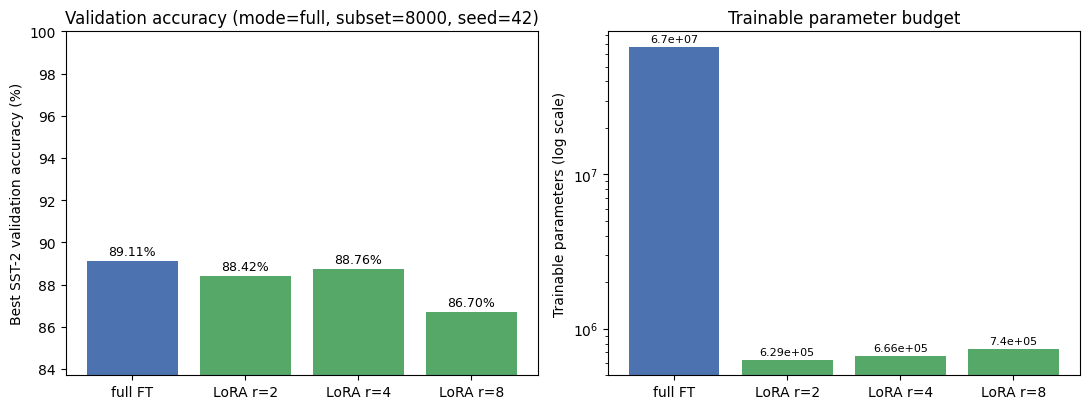

In [47]:
# 10) Plots: accuracy + parameter efficiency ----------------------------------
import matplotlib.pyplot as plt

order = {n: i for i, n in enumerate(["full", "lora_r2_a4", "lora_r4_a8", "lora_r8_a16"])}
df["_o"] = df["run_name"].map(lambda n: order.get(n, 99))
d = df.sort_values("_o")
xlabels = [f"full FT" if r.method == "full" else f"LoRA r={int(r.rank)}" for r in d.itertuples()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
colors = ["#4C72B0" if m == "full" else "#55A868" for m in d["method"]]
b1 = ax1.bar(xlabels, d["best_val_acc"].astype(float) * 100, color=colors)
ax1.bar_label(b1, fmt="%.2f%%", padding=2, fontsize=9)
ax1.set_ylim(float(d["best_val_acc"].astype(float).min()) * 100 - 3, 100)
ax1.set_ylabel("Best SST-2 validation accuracy (%)")
ax1.set_title(f"Validation accuracy (mode={MODE}, subset={cfg.subset}, seed={cfg.seed})")

b2 = ax2.bar(xlabels, d["trainable_params"].astype(float), color=colors)
ax2.set_yscale("log")
ax2.bar_label(b2, fmt="%.3g", padding=2, fontsize=8)
ax2.set_ylabel("Trainable parameters (log scale)")
ax2.set_title("Trainable parameter budget")
plt.tight_layout(); plt.show()

## 11. Peak GPU memory and training time

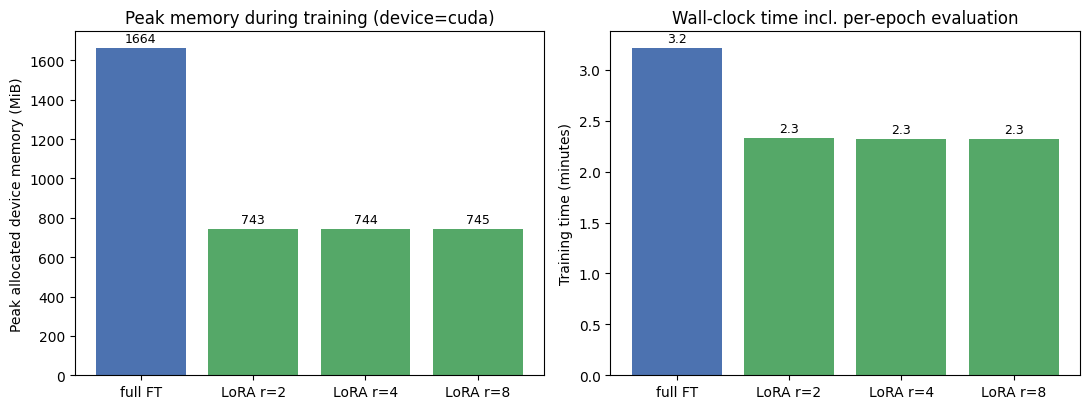

Note: LoRA cuts gradient/optimizer-state memory, but the frozen backbone must still be stored and processed, so parameter/activation memory remains.


In [48]:
# 11) Memory + wall-clock comparison ------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

mem = pd.to_numeric(d["peak_gpu_mem_mib"], errors="coerce")
if mem.notna().any():
    b = ax1.bar(xlabels, mem, color=colors)
    ax1.bar_label(b, fmt="%.0f", padding=2, fontsize=9)
    ax1.set_ylabel("Peak allocated device memory (MiB)")
    ax1.set_title(f"Peak memory during training (device={DEVICE})")
else:
    ax1.text(0.5, 0.5, "no GPU memory measurement\n(CPU run)", ha="center", va="center")
    ax1.set_axis_off()

t = d["train_time_sec"].astype(float) / 60
b = ax2.bar(xlabels, t, color=colors)
ax2.bar_label(b, fmt="%.1f", padding=2, fontsize=9)
ax2.set_ylabel("Training time (minutes)")
ax2.set_title("Wall-clock time incl. per-epoch evaluation")
plt.tight_layout(); plt.show()

print("Note: LoRA cuts gradient/optimizer-state memory, but the frozen backbone "
      "must still be stored and processed, so parameter/activation memory remains.")

In [49]:
import pandas as pd
df = pd.read_csv('/content/DL051-LoRA/results/notebook_full/results.csv')
print(df[['run_name','best_val_acc','subset_size','epochs','device']])

      run_name  best_val_acc  subset_size  epochs device
0         full        0.8911         8000       2   cuda
1   lora_r2_a4        0.8842         8000       2   cuda
2   lora_r4_a8        0.8876         8000       2   cuda
3  lora_r8_a16        0.8670         8000       2   cuda


In [57]:
from google.colab import files
import os

# Configure the directory path directly to avoid NameError
MODE = os.environ.get("DL051_MODE", "full")
RESULTS_DIR = f"/content/DL051-LoRA/results/notebook_{MODE}"

results_csv = os.path.join(RESULTS_DIR, 'results.csv')
log_csv = os.path.join(RESULTS_DIR, 'experiment_log.csv')

if os.path.exists(results_csv):
    print(f"Downloading: {results_csv}")
    files.download(results_csv)
else:
    print(f"File not found: {results_csv}")

if os.path.exists(log_csv):
    print(f"Downloading: {log_csv}")
    files.download(log_csv)
else:
    print(f"File not found: {log_csv}")

Downloading: /content/DL051-LoRA/results/notebook_full/results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: /content/DL051-LoRA/results/notebook_full/experiment_log.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Discussion and limitations

* **What the paper reports vs what we measure.** The paper's GLUE table
  (RoBERTa-large): full FT 96.4 vs LoRA r=4 96.2 ± 0.5 SST-2 accuracy, with
  0.8M trainable vs 355M. Our runs are a *different, smaller* setting
  (DistilBERT-66M, ≤8k training examples, 2 epochs, single seed): absolute
  accuracies are not comparable to the paper's; the *pattern* (LoRA close to
  full FT at a tiny fraction of trainable parameters, rank barely moving the
  needle beyond small r) is what we check.
* **Rank ablation.** Per adapted layer the adapter costs $r(d+k)$ parameters:
  linear in $r$. The paper found little benefit from large ranks for $W_q,W_v$
  (r=1 already competitive on GPT-3 tasks); we test whether accuracy saturates
  at small r on our setting.
* **Limitations.** Single seed; validation used for both evaluation and model
  selection (GLUE test labels are withheld); reduced training subset; local
  GPU is Apple MPS, not the Colab T4 the notebook targets; 2 epochs only.
  Peak memory on MPS is sampled per batch, on CUDA it is exact allocator peak.
* **Failure cases.** Small subsets make runs noisy: with 8k examples a ±0.5%
  accuracy difference between ranks is within seed noise and must not be
  over-interpreted.

## 13. Conclusion

The custom LoRA layer reproduces the paper's core claim at reduced scale: a
low-rank update on the query/value projections, with the backbone frozen,
trains orders of magnitude fewer parameters than full fine-tuning while staying
close in SST-2 validation accuracy, with zero extra inference cost after merging
$W' = W_0 + (\frac{\alpha}{r})BA$. Rank controls the capacity/parameter trade-off
linearly; beyond a small rank the accuracy gains saturate in our setting.

**References**
1. Hu et al. *LoRA: Low-Rank Adaptation of Large Language Models*, ICLR 2022. arXiv:2106.09685
2. Sanh et al. *DistilBERT, a distilled version of smaller, faster, lighter BERT*, NeurIPS-W 2019.
3. Socher et al. *Recursive Deep Models for Semantic Compositionality*, EMNLP 2013 (SST).
4. Wang et al. *GLUE: A Multi-Task Benchmark*, EMNLP-W 2018.